# 4. Baseline Model

This notebook establishes the first machine learning baseline for delivery-time prediction.

The objective is to predict total delivery time in minutes using the features defined during data preparation.

The baseline provides a reference performance level against which more advanced models will be compared.

The test set will remain untouched during model development and will only be used for final evaluation.

In [1]:
! pip install scikit-learn


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

from  sklearn.compose import ColumnTransformer
from  sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.dummy import DummyRegressor

In [3]:
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DATA_PATH = PROJECT_ROOT / "Data" / 'Processed'

print("Project root :",PROJECT_ROOT)
print('Processed data path :',PROCESSED_DATA_PATH)

Project root : c:\Users\A MAHESH\OneDrive\Desktop\INNOMATICS-DS\ML project\Last-mile-Delivery-Intillegence
Processed data path : c:\Users\A MAHESH\OneDrive\Desktop\INNOMATICS-DS\ML project\Last-mile-Delivery-Intillegence\Data\Processed


In [4]:
list(PROCESSED_DATA_PATH.iterdir())

[WindowsPath('c:/Users/A MAHESH/OneDrive/Desktop/INNOMATICS-DS/ML project/Last-mile-Delivery-Intillegence/Data/Processed/cleaned_data.csv')]

In [5]:
# Load the Data

DATA_PATH = PROCESSED_DATA_PATH / 'cleaned_data.csv'

df = pd.read_csv(DATA_PATH)

print("Dataset shape :",df.shape)
df.head()

Dataset shape : (41953, 38)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,pickup_day_name,pickup_is_weekend,pickup_time_period,pickup_hour_sin,pickup_hour_cos,order_timestamp,order_to_pickup_minutes,is_peak_pickup,distance_km,distance_bands
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:33:33,...,Saturday,True,afternoon,0.258819,-9.659258e-01,2022-03-19 11:33:33,11.933333,True,3.025149,medium
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:37,...,Friday,False,night,-0.965926,2.588190e-01,2022-03-25 19:45:37,6.200000,True,20.183530,very_long
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,8:32:58,...,Saturday,True,morning,0.866025,-5.000000e-01,2022-03-19 08:32:58,15.816667,False,1.552758,short
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:03:58,...,Tuesday,False,evening,-1.000000,-1.836970e-16,2022-04-05 18:03:58,8.900000,False,7.790401,long
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:34:16,...,Saturday,True,afternoon,-0.258819,-9.659258e-01,2022-03-26 13:34:16,11.333333,True,6.210138,long


In [6]:
# verfying the target Date
df['order_date'] = pd.to_datetime(df['order_date'],errors = 'coerce')

print('Dataset shape :',df.shape)
print('missing order dates :',df['order_date'].isna().sum())
print('Missing target values :',df['target_delivery_time'].isna().sum())

print('\nDate range :')
print(df['order_date'].min(), '->',df['order_date'].max())


print('\nTarget Summary:')
print(df['target_delivery_time'].describe())

Dataset shape : (41953, 38)
missing order dates : 0
Missing target values : 0

Date range :
2022-02-11 00:00:00 -> 2022-04-06 00:00:00

Target Summary:
count    41953.000000
mean        26.311539
std          9.380753
min         10.000000
25%         19.000000
50%         26.000000
75%         32.000000
max         54.000000
Name: target_delivery_time, dtype: float64


In [7]:
# Recreating chronological Split

unique_dates = (df['order_date'].dropna().sort_values().unique())

n_dates = len(unique_dates)

train_end_idx = int(n_dates * 0.70)
validation_end_idx = int(n_dates * 0.85)

train_end_date = unique_dates[train_end_idx - 1]
validation_end_date = unique_dates[validation_end_idx - 1]

print("Train end date :",train_end_date)
print('Validation end date :',validation_end_date)
print("Test start date :",unique_dates[validation_end_idx])


Train end date : 2022-03-23 00:00:00
Validation end date : 2022-03-30 00:00:00
Test start date : 2022-03-31 00:00:00


In [8]:
# Create  TRAIN,VALIDATION AND TEST

train_df = (
    df[df["order_date"] <= train_end_date]
    .sort_values("order_date")
    .copy()
)

validation_df = (
    df[
        (df["order_date"] > train_end_date) &
        (df["order_date"] <= validation_end_date)
    ]
    .sort_values("order_date")
    .copy()
)

test_df = (
    df[df["order_date"] > validation_end_date]
    .sort_values("order_date")
    .copy()
)



In [9]:
# Verify the Split

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

print('\nDate ranges :')

print("Train :",train_df['order_date'].min(),
      "->" , train_df['order_date'].max())

print("Validation :",validation_df['order_date'].min(),
                                 "->",validation_df['order_date'].max()
)

print(
    "Test:",
    test_df["order_date"].min(),
    "→",
    test_df["order_date"].max()
)

Train: (28034, 38)
Validation: (7050, 38)
Test: (6869, 38)

Date ranges :
Train : 2022-02-11 00:00:00 -> 2022-03-23 00:00:00
Validation : 2022-03-24 00:00:00 -> 2022-03-30 00:00:00
Test: 2022-03-31 00:00:00 → 2022-04-06 00:00:00


In [10]:

target_column = "target_delivery_time"

feature_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "distance_km",
    "distance_bands",
    "pickup_hour",
    "pickup_minute",
    "pickup_day_of_week",
    "pickup_is_weekend",
    "pickup_time_period",
    "pickup_hour_sin",
    "pickup_hour_cos",
    "is_peak_pickup",
    "Weatherconditions",
    "Road_traffic_density",
    "Vehicle_condition",
    "Type_of_order",
    "Type_of_vehicle",
    "multiple_deliveries",
    "Festival",
    "City",
]

In [11]:
X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_validation = validation_df[feature_columns].copy()
y_validation = validation_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

In [12]:
# check the shape of all 

print('X_train :',X_train.shape)
print('y_train :',y_train.shape)

print("X_validation :",X_validation.shape)
print('y_validation :',y_validation.shape)


print('X_test :',X_test.shape)
print('y_test:',y_test.shape)

X_train : (28034, 24)
y_train : (28034,)
X_validation : (7050, 24)
y_validation : (7050,)
X_test : (6869, 24)
y_test: (6869,)


In [13]:
print('Target:',target_column)

print("\nTarget included in features :",target_column in feature_columns)

print('\nNumber of features :',len(feature_columns))

Target: target_delivery_time

Target included in features : False

Number of features : 24


In [14]:
# Separate numerical and categorical Features

categorical_features = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City",
    "pickup_time_period",
    "distance_bands",
]

numerical_features = [
    feature
    for feature in feature_columns
    if feature not in categorical_features
]

print("Number of numerical features :",len(numerical_features))
print('Number of categorical features :',len(categorical_features))

print('\nNumerical_features :')
print(numerical_features)

print('\nCategorical features :')
print(categorical_features)

Number of numerical features : 16
Number of categorical features : 8

Numerical_features :
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'distance_km', 'pickup_hour', 'pickup_minute', 'pickup_day_of_week', 'pickup_is_weekend', 'pickup_hour_sin', 'pickup_hour_cos', 'is_peak_pickup', 'Vehicle_condition', 'multiple_deliveries']

Categorical features :
['Weatherconditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City', 'pickup_time_period', 'distance_bands']


In [15]:
# checking missing values in training_data

missing_train = (
    X_train.isna().sum().sort_values(ascending = False)
)

missing_train[missing_train > 0]

Delivery_person_Ratings    1189
Delivery_person_Age        1145
City                        722
multiple_deliveries         595
Weatherconditions           392
Road_traffic_density        378
Festival                    131
dtype: int64

In [16]:
missing_train_pct = (
    X_train.isna().mean() * 100).sort_values(ascending = False)
missing_train_pct[missing_train_pct > 0]

Delivery_person_Ratings    4.241278
Delivery_person_Age        4.084326
City                       2.575444
multiple_deliveries        2.122423
Weatherconditions          1.398302
Road_traffic_density       1.348363
Festival                   0.467290
dtype: float64

In [17]:
# Build numerical preprocessing

numerical_pipeline = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy='median')
        )
    ]
)

In [18]:
# Build categorical preprocessing

categorical_pipeline = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy='most_frequent')),
        ('onehot',OneHotEncoder(handle_unknown='ignore',
        sparse_output = False
)
)
]
)

In [19]:
# Combine the preprocessing the pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical",
         numerical_pipeline,
         numerical_features
         ),
         (
             'categorical',
             categorical_pipeline,
             categorical_features
         )
    ]
)

In [20]:
# CHeck the pre-processing pipeline

X_train_processed = preprocessor.fit_transform(X_train)

X_validation_processed = preprocessor.transform(X_validation)

print("Processed training shape :",X_train_processed.shape)

print("Processed validation shape :",X_validation_processed.shape)

Processed training shape : (28034, 48)
Processed validation shape : (7050, 48)


In [21]:
# Check no msising values remain
print(
    'Missing values in processed training data :',
    np.isnan(X_train_processed).sum()
)

print(
    'Missing values in processed validation data :',
    np.isnan(X_validation_processed).sum()
)

Missing values in processed training data : 0
Missing values in processed validation data : 0


In [22]:
# Dummy BaseLine Model

dummy_model = DummyRegressor(
    strategy='mean'
)
dummy_model.fit(
    X_train_processed,
    y_train
)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[26.39]]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,48
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [23]:
y_validation_Dummy = dummy_model.predict(
    X_validation_processed
)

print(y_validation_Dummy[:10])

[26.3856032 26.3856032 26.3856032 26.3856032 26.3856032 26.3856032
 26.3856032 26.3856032 26.3856032 26.3856032]


In [24]:
# Calculate Baseline Metrics
dummy_mae = mean_absolute_error(
    y_validation,
    y_validation_Dummy
)

dummy_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        y_validation_Dummy
    )
)


dummy_r2 = r2_score(
    y_validation,
    y_validation_Dummy
)

print('Dummy Baseline - Validation')
print("---------------------------")
print(f"MAE : {dummy_mae:.3f} minutes")
print(f"RMSE :{dummy_rmse:.3f} minutes")
print(f"R2 : {dummy_r2:.3f}")

Dummy Baseline - Validation
---------------------------
MAE : 7.600 minutes
RMSE :9.366 minutes
R2 : -0.004


In [25]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps = [
        ("preprocessor",preprocessor),
        ("model",LinearRegression())
    ]
)

In [26]:
# Train the Model

linear_model.fit(
    X_train,y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Delivery_person_Age','Delivery_person_Ratings','Restaurant_latitude',..., 'multiple_deliveries','Festival','City']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` w

In [27]:
# predict validation delivery Times
y_validation_linear = linear_model.predict(
    X_validation
)
print(y_validation_linear[:10])

[17.47661918 31.33965903 33.54952325 29.07238297 35.80208889 28.68039752
 23.83548699 27.148452   14.80813518 18.93086599]


In [28]:
# Evaluate Linear Regression

linear_mae = mean_absolute_error(
    y_validation,
    y_validation_linear
)

linear_rmse = np.sqrt(
    mean_squared_error(y_validation,
                       y_validation_linear)
)

linear_r2 = r2_score(
    y_validation,
    y_validation_linear
)
print("Linear regression - Validation")
print("------------------------------")
print(f"MAE : {linear_mae:.3f} minutes")
print(f"RMSE : {linear_rmse:.3f} minutes")
print(f"R2   : {linear_r2:.3f}")

Linear regression - Validation
------------------------------
MAE : 4.699 minutes
RMSE : 5.904 minutes
R2   : 0.601


In [29]:
baseline_results = pd.DataFrame({
    "Model": [
        "Dummy Mean",
        "Linear Regression"
    ],
    "MAE": [
        dummy_mae,
        linear_mae
    ],
    "RMSE": [
        dummy_rmse,
        linear_rmse
    ],
    "R2": [
        dummy_r2,
        linear_r2
    ]
})

baseline_results

,Model,MAE,RMSE,R2
0,Dummy Mean,7.599601,9.365807,-0.004453
1,Linear Regression,4.698673,5.904334,0.600809


In [30]:
# CHecking descision Tree

from sklearn.tree import DecisionTreeRegressor

In [31]:
decision_tree_model = Pipeline(
    steps =  [
        ('preprocessor',preprocessor),
        ('model',DecisionTreeRegressor(random_state=42))
    ]
)

In [32]:
decision_tree_model.fit(
    X_train,y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Delivery_person_Age','Delivery_person_Ratings','Restaurant_latitude',..., 'multiple_deliveries','Festival','City']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` w

In [33]:
y_validation_tree = decision_tree_model.predict(
    X_validation )
print(y_validation_tree[:10]
)

[24. 25. 43. 38. 31. 29. 34. 16. 15. 21.]


In [34]:
# Evaluate the decsion Tree
tree_mae = mean_absolute_error(y_validation,y_validation_tree)

tree_rmse = np.sqrt(
    mean_squared_error(
        y_validation,y_validation_tree
    )
)

tree_r2 = r2_score(
    y_validation,y_validation_tree
)

print("Decision Tree - Validation")
print("--------------------------")
print(f"MAE :  {tree_mae:.3f} minutes")
print(f"RMSE:  {tree_rmse:.3f} minutes")
print(f"R²  :  {tree_r2:.3f}")

Decision Tree - Validation
--------------------------
MAE :  4.216 minutes
RMSE:  5.555 minutes
R²  :  0.647


In [35]:
# Make comparasion table

baseline_results = pd.DataFrame({
    "Model": [
        "Dummy Mean",
        "Linear Regression",
        "Decision Tree"
    ],
    "MAE": [
        dummy_mae,
        linear_mae,
        tree_mae
    ],
    "RMSE": [
        dummy_rmse,
        linear_rmse,
        tree_rmse
    ],
    "R2": [
        dummy_r2,
        linear_r2,
        tree_r2
    ]
})

baseline_results

,Model,MAE,RMSE,R2
0,Dummy Mean,7.599601,9.365807,-0.004453
1,Linear Regression,4.698673,5.904334,0.600809
2,Decision Tree,4.216312,5.554744,0.646681


In [36]:
# Try XGBoost Model
! pip install xgboost



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
from xgboost import XGBRegressor

In [38]:
xgb_model = Pipeline(
    steps = [
        ('preprocessor',preprocessor),
        ("Model",XGBRegressor(
            objective = "reg:squarederror",
            n_estimators = 300,
            learning_rate = 0.05,
            max_depth = 6,
            subsample = 0.8,
            colsample_bytree = 0.8,
            random_state = 42,
            n_jobs = -1
        ))
    ]
)

In [39]:
# TRain
xgb_model.fit(
    X_train,y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Delivery_person_Age','Delivery_person_Ratings','Restaurant_latitude',..., 'multiple_deliveries','Festival','City']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` w

In [40]:
y_validation_xgb = xgb_model.predict(
    X_validation)

print(y_validation_xgb[:10])

[21.717304 27.878033 38.218277 34.858883 29.943052 28.71172  32.587383
 18.44627  14.080238 21.48432 ]


In [41]:
xgb_mae = mean_absolute_error(
    y_validation,y_validation_xgb)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation,y_validation_xgb
    )
)

xgb_r2 = r2_score(
    y_validation,y_validation_xgb
)


print("XGBoost - Validation")
print("--------------------")
print(f"MAE :  {xgb_mae:.3f} minutes")
print(f"RMSE:  {xgb_rmse:.3f} minutes")
print(f"R²  :  {xgb_r2:.3f}")

XGBoost - Validation
--------------------
MAE :  3.172 minutes
RMSE:  4.010 minutes
R²  :  0.816


In [42]:
# Comparasion Table

baseline_results = pd.DataFrame({
    "Model": [
        "Dummy Mean",
        "Linear Regression",
        "Decision Tree",
        "XGBoost"
    ],
    "MAE": [
        dummy_mae,
        linear_mae,
        tree_mae,
        xgb_mae
    ],
    "RMSE": [
        dummy_rmse,
        linear_rmse,
        tree_rmse,
        xgb_rmse
    ],
    "R2": [
        dummy_r2,
        linear_r2,
        tree_r2,
        xgb_r2
    ]
})

baseline_results

,Model,MAE,RMSE,R2
0,Dummy Mean,7.599601,9.365807,-0.004453
1,Linear Regression,4.698673,5.904334,0.600809
2,Decision Tree,4.216312,5.554744,0.646681
3,XGBoost,3.171558,4.009719,0.815894


In [43]:
# inspect the model comparasion
baseline_results.sort_values("MAE")

,Model,MAE,RMSE,R2
3,XGBoost,3.171558,4.009719,0.815894
2,Decision Tree,4.216312,5.554744,0.646681
1,Linear Regression,4.698673,5.904334,0.600809
0,Dummy Mean,7.599601,9.365807,-0.004453


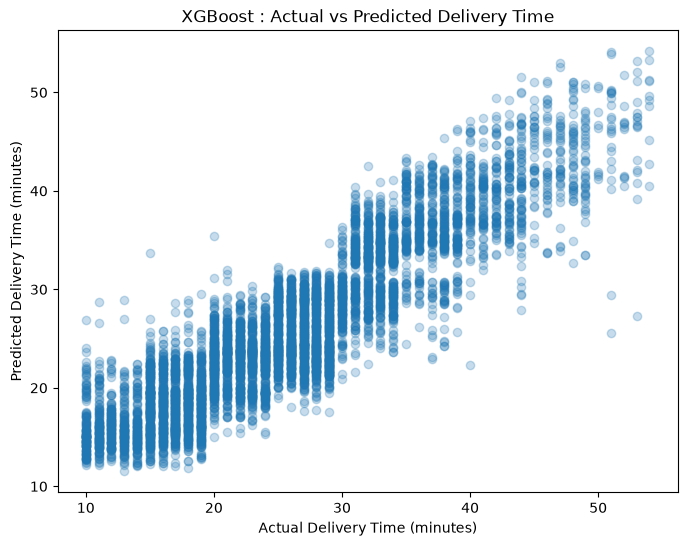

In [44]:
# visualize actual vs predicted
import matplotlib.pyplot as plt

plt.figure(figsize = (8,6))
plt.scatter(y_validation,y_validation_xgb,alpha = 0.25)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("XGBoost : Actual vs Predicted Delivery Time")

plt.show()

In [45]:
# Examine prediction errors

validation_errors = y_validation - y_validation_xgb
error_summary  = pd.Series(validation_errors).describe()

error_summary

count    7050.000000
mean       -0.125760
std         4.008031
min       -18.710560
25%        -2.824502
50%        -0.326674
75%         2.486077
max        25.721758
Name: target_delivery_time, dtype: float64

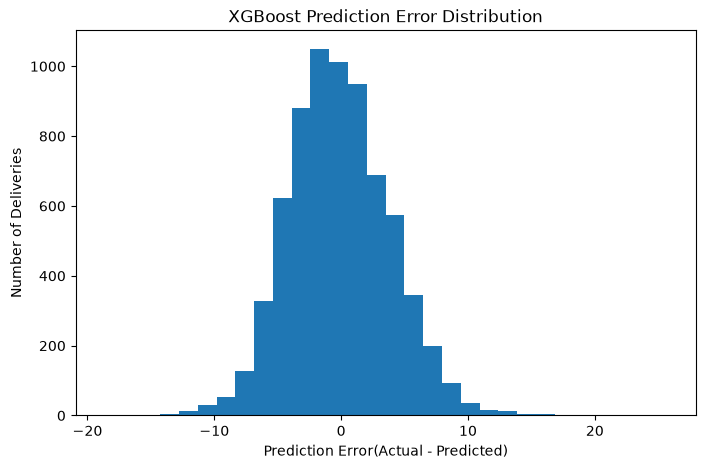

In [46]:
plt.figure(figsize=(8,5))
plt.hist(validation_errors,bins = 30)

plt.xlabel("Prediction Error(Actual - Predicted)")
plt.ylabel("Number of Deliveries")
plt.title("XGBoost Prediction Error Distribution")

plt.show()

In [47]:
# Checking feature Importance
# Because our model is inside a pipeline, first extract the trained XGBoost model:
xgb_trained_model = xgb_model.named_steps["Model"]



In [48]:
# extracting the feature names
feature_names = (
    xgb_model.named_steps['preprocessor'].get_feature_names_out() )

feature_importance = pd.DataFrame({
    'feature' : feature_names,
    'importance' : xgb_trained_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values('importance',ascending = False).reset_index(drop = True)
)


feature_importance.head(15)

,feature,importance
0,categorical__pickup_time_period_morning,0.203632
1,categorical__Road_traffic_density_Low,0.128608
2,categorical__distance_bands_very_long,0.113407
3,numerical__multiple_deliveries,0.063191
4,categorical__Weatherconditions_Sunny,0.057748
5,numerical__Delivery_person_Ratings,0.053653
6,categorical__Road_traffic_density_Jam,0.041487
7,categorical__Weatherconditions_Cloudy,0.039752
8,categorical__Festival_No,0.038746
9,numerical__Vehicle_condition,0.036924


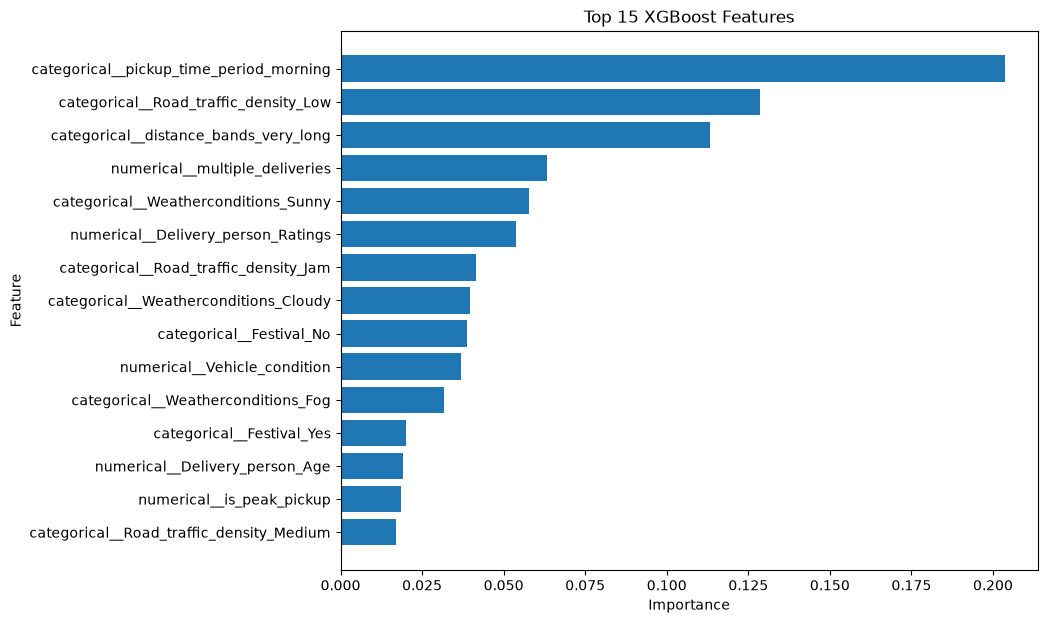

In [49]:
top_features = feature_importance.head(15).sort_values('importance')

plt.figure(figsize=(9,7))

plt.barh(
    top_features['feature'],
    top_features['importance']
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title('Top 15 XGBoost Features')

plt.show()

In [50]:
# XBBoost hyperparameter Tuning
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint,uniform

In [51]:
# create the tuning parameters space

xgb_param_distributions = {
    "Model__n_estimators": randint(200, 700),
    "Model__max_depth": randint(3, 10),
    "Model__learning_rate": uniform(0.02, 0.18),
    "Model__subsample": uniform(0.7, 0.3),
    "Model__colsample_bytree": uniform(0.7, 0.3),
    "Model__min_child_weight": randint(1, 10),
    "Model__gamma": uniform(0, 0.5),
    "Model__reg_alpha": uniform(0, 0.5),
    "Model__reg_lambda": uniform(0.5, 2.0)
}

# these parameters control model complexity, learning speed, sampling, and regularization. 
# The ranges are intentionally moderate so the search remains computationally practical.

In [52]:
# configure Randomzied search CV
xgb_random_search = RandomizedSearchCV(
    estimator = xgb_model,
    param_distributions = xgb_param_distributions,
    n_iter = 20,
    scoring = "neg_mean_absolute_error",
    cv = 3,
    verbose=1,
    random_state=42,
    n_jobs = -1
)

In [53]:
# Run the search
xgb_random_search.fit(
    X_train,y_train
)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'Model__colsample_bytree': <scipy.stats....001DF9E1D3610>, 'Model__gamma': <scipy.stats....001DF9E0AC2B0>, 'Model__learning_rate': <scipy.stats....001DF9E01ECF0>, 'Model__max_depth': <scipy.stats....001DF9E12AFD0>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are consi

In [54]:
print("Best Parameters :")
print(xgb_random_search.best_params_)

Best Parameters :
{'Model__colsample_bytree': np.float64(0.9921266556524377), 'Model__gamma': np.float64(0.11638567021515211), 'Model__learning_rate': np.float64(0.036309158215907744), 'Model__max_depth': 8, 'Model__min_child_weight': 3, 'Model__n_estimators': 563, 'Model__reg_alpha': np.float64(0.2571172192068058), 'Model__reg_lambda': np.float64(1.684829137724085), 'Model__subsample': np.float64(0.7139351238159992)}


In [55]:
# Best cross_val
print("Best CV MAE :")
print(-xgb_random_search.best_score_)

Best CV MAE :
3.1885403792063394


In [56]:
# Evaluating the tuned Model on our validation set
tuned_xgb_model = xgb_random_search.best_estimator_
y_validation_tuned = tuned_xgb_model.predict(X_validation)

In [57]:
tuned_xgb_mae = mean_absolute_error(
    y_validation,y_validation_tuned
)
tuned_xgb_rmse = np.sqrt(
    mean_squared_error(y_validation,y_validation_tuned)
)

tuned_xgb_r2 = r2_score(
    y_validation,y_validation_tuned
)

print("Tuned XGBoost - Validation")
print("--------------------------")
print(f"MAE :  {tuned_xgb_mae:.3f} minutes")
print(f"RMSE:  {tuned_xgb_rmse:.3f} minutes")
print(f"R²  :  {tuned_xgb_r2:.3f}")

Tuned XGBoost - Validation
--------------------------
MAE :  3.144 minutes
RMSE:  3.968 minutes
R²  :  0.820


In [58]:
# create a validation error dataset
error_analysis = X_validation.copy()
error_analysis['actual_delivery_time'] = y_validation.values
error_analysis['predicted_delivery_time'] = y_validation_tuned
error_analysis['prediction_error'] = (
    error_analysis['actual_delivery_time'] - error_analysis['predicted_delivery_time']
)

error_analysis['absolute_error'] = (
    error_analysis['prediction_error'].abs())

error_analysis.head()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,distance_km,distance_bands,pickup_hour,pickup_minute,...,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,actual_delivery_time,predicted_delivery_time,prediction_error,absolute_error
21084,NaN,NaN,18.546258,73.904337,18.566258,73.924337,3.064405,medium,8,47,...,1,Meal,scooter,0.0,No,Metropolitian,17,21.744802,-4.744802,4.744802
18047,34.0,4.8,22.311844,73.165081,22.341844,73.195081,4.544208,medium,18,19,...,0,Drinks,motorcycle,NaN,No,Metropolitian,26,28.545588,-2.545588,2.545588
18037,36.0,4.0,22.748060,75.893400,22.808060,75.953400,9.074745,long,21,59,...,0,Drinks,motorcycle,0.0,No,Metropolitian,31,37.585732,-6.585732,6.585732
18004,25.0,4.9,13.026279,80.174568,13.066279,80.214568,6.209485,long,12,33,...,0,Meal,motorcycle,2.0,No,Metropolitian,37,37.036583,-0.036583,0.036583
17983,38.0,4.8,12.933284,77.615428,12.983284,77.665428,7.763197,long,19,38,...,0,Meal,motorcycle,1.0,No,Metropolitian,26,28.634464,-2.634464,2.634464


In [59]:
# Summarize the distribution of prediction errors.
# This tells us whether the model is generally unbiased and how large the errors are.

error_analysis[
    [ "prediction_error",
     "absolute_error"]
].describe()


,prediction_error,absolute_error
count,7050.000000,7050.000000
mean,-0.118116,3.143554
std,3.966694,2.421834
min,-19.888603,0.000956
25%,-2.840075,1.265121
50%,-0.313789,2.659466
75%,2.450332,4.440736
max,23.683628,23.683628


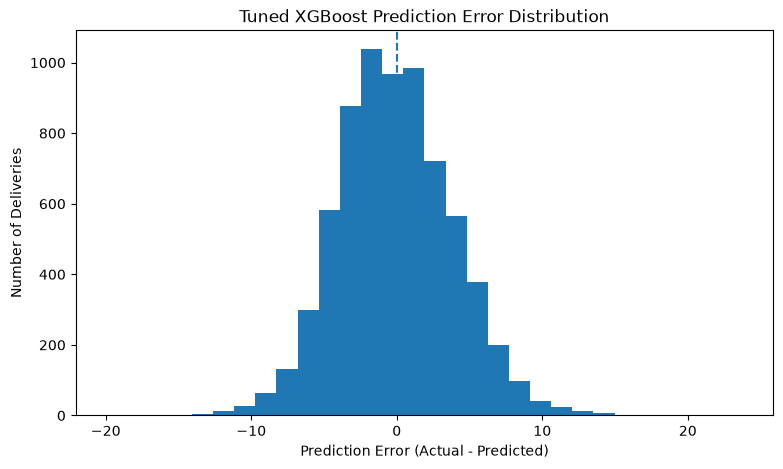

In [60]:
import matplotlib.pyplot as plt
plt.figure(figsize = (9,5))
plt.hist(error_analysis['prediction_error'],bins = 30)
plt.axvline(0,linestyle = "--")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Deliveries")
plt.title("Tuned XGBoost Prediction Error Distribution")

plt.show()

In [61]:
# finding the largest errors
# Identify deliveries where the model made its largest absolute errors.
# These cases are important because they represent situations where the ETA system
# could be least reliable.
largest_errors = (
    error_analysis
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(20)
)

largest_errors[
    [
        "actual_delivery_time",
        "predicted_delivery_time",
        "prediction_error",
        "absolute_error",
        "distance_km",
        "Road_traffic_density",
        "Weatherconditions",
        "City"
    ]
]


,actual_delivery_time,predicted_delivery_time,prediction_error,absolute_error,distance_km,Road_traffic_density,Weatherconditions,City
28436,53,29.316372,23.683628,23.683628,6.116387,High,Sunny,Metropolitian
1612,15,34.888603,-19.888603,19.888603,17.137528,NaN,NaN,Metropolitian
10514,40,21.038290,18.961710,18.961710,12.074056,NaN,NaN,Urban
18905,10,28.835728,-18.835728,18.835728,19.659793,NaN,NaN,Urban
23766,11,28.742426,-17.742426,17.742426,4.674324,Jam,Sandstorms,Metropolitian
388,13,29.277096,-16.277096,16.277096,4.663432,Medium,Stormy,Metropolitian
28109,20,36.182438,-16.182438,16.182438,20.852514,Medium,Sandstorms,Metropolitian
38207,51,35.180504,15.819496,15.819496,6.232321,High,Sunny,Urban
16684,44,28.958807,15.041193,15.041193,6.081389,High,Sunny,Metropolitian
18917,11,26.014923,-15.014923,15.014923,6.210045,High,Windy,Metropolitian


In [62]:
# Underprediction vs overprediction

under_predictions = (error_analysis['prediction_error'] > 0).sum()

over_predictions = (error_analysis['prediction_error'] < 0).sum()

accurate_predictions = (error_analysis['prediction_error'] == 0).sum()

print("Under_predictions :",under_predictions)
print("over_predictions :",over_predictions)
print("Accurate_prediction",accurate_predictions)

Under_predictions : 3330
over_predictions : 3720
Accurate_prediction 0


In [63]:
print(f"Mean prediction error :"f"{error_analysis['prediction_error'].mean():.3f} minutes")

Mean prediction error :-0.118 minutes


In [64]:
# error by trafic density
traffic_error = (error_analysis.groupby('Road_traffic_density',dropna = False)
                 .agg(deliveries = ('absolute_error','size'),
                      MAE = ("absolute_error",'mean'),
                      mean_error = ('prediction_error','mean')).sort_values("MAE",ascending=False))

traffic_error

,deliveries,MAE,mean_error
Road_traffic_density,,,
NaN,86,5.894392,0.351323
Jam,2139,3.538359,0.028067
High,810,3.342322,-0.006581
Medium,1583,3.024880,-0.323630
Low,2432,2.710084,-0.166664


In [65]:
# error by distance
error_analysis['distance_group'] = pd.cut(
    error_analysis['distance_km'],bins=[0,5,10,15,21],labels=["0-5 km",
        "5-10 km",
        "10-15 km",
        "15-21 km"],
        include_lowest=True
)

distance_error = (error_analysis.groupby('distance_group',observed=False).agg(deliveries=('absolute_error','size'),
                                                                              MAE=('absolute_error','mean'),
                                                                              mean_error=('prediction_error','mean')))
distance_error

,deliveries,MAE,mean_error
distance_group,,,
0-5 km,2147,2.919949,-0.103941
5-10 km,2170,3.034962,-0.169030
10-15 km,1607,3.349846,-0.143124
15-21 km,1126,3.484774,-0.011331


In [66]:
# error by city
city_error = error_analysis.groupby("City",dropna=False).agg(
    deliveries = ('absolute_error','size'),
    MAE = ('absolute_error','mean'),
    mean_error = ('prediction_error','mean')
).sort_values("MAE",ascending = False)

city_error

,deliveries,MAE,mean_error
City,,,
NaN,210,3.659017,-1.365222
Urban,1549,3.211699,-0.222090
Metropolitian,5268,3.104137,-0.040045
Semi-Urban,23,2.875947,0.389383


# SHAP Explanibility

SHAP explains how individual features contribute to the XGBoost prediction.

 We start with global feature importance before investigating individual deliveries.

In [67]:
import shap

print(shap.__version__)

0.52.0


In [68]:
# Extract the fitted preprocessing and XGBoost components.
# SHAP will explain the trained XGBoost model using the same transformed
# features that were used during model prediction.

trained_preprocessor = tuned_xgb_model.named_steps['preprocessor']
trained_xgb = tuned_xgb_model.named_steps['Model']

X_validation_processed = trained_preprocessor.transform(X_validation)

feature_names = (trained_preprocessor.get_feature_names_out())

print('Processed validation shape :',X_validation_processed.shape)
print('Number of feature names :',len(feature_names))


Processed validation shape : (7050, 48)
Number of feature names : 48


In [69]:
# create the SHAP explainer
explainer = shap.TreeExplainer(trained_xgb)

In [70]:
# Calculate SHAP values for the validation dataset.
# These values quantify each feature's contribution to the model predictions.

shap_values = explainer.shap_values(X_validation_processed)

print('SHAP values shape :',shap_values.shape)

SHAP values shape : (7050, 48)


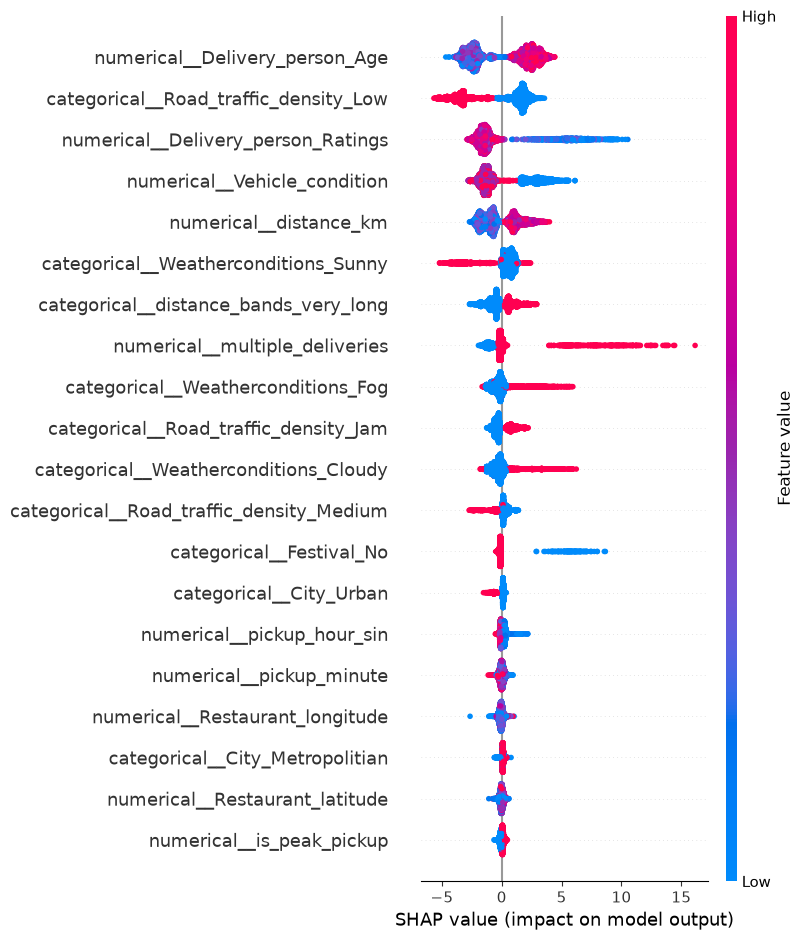

In [71]:
# Global SHAP summary
shap.summary_plot(
    shap_values,X_validation_processed,feature_names = feature_names
)

In [72]:
# LOCAL SHAP
# Select one validation delivery for a local SHAP explanation.
# We use an actual observation from the validation set so the explanation
# corresponds to a real prediction made by our tuned model.

sample_index = 0
sample_features = X_validation_processed[
    sample_index : sample_index + 1 ]

sample_shap_values = shap_values[sample_index]

sample_prediction = tuned_xgb_model.predict(X_validation.iloc[[sample_index]])[0]

print(
    f"Predicted delivery time: "
    f"{sample_prediction:.2f} minutes"
)

print(
    f"Actual delivery time: "
    f"{y_validation.iloc[sample_index]:.2f} minutes"
)

Predicted delivery time: 21.74 minutes
Actual delivery time: 17.00 minutes


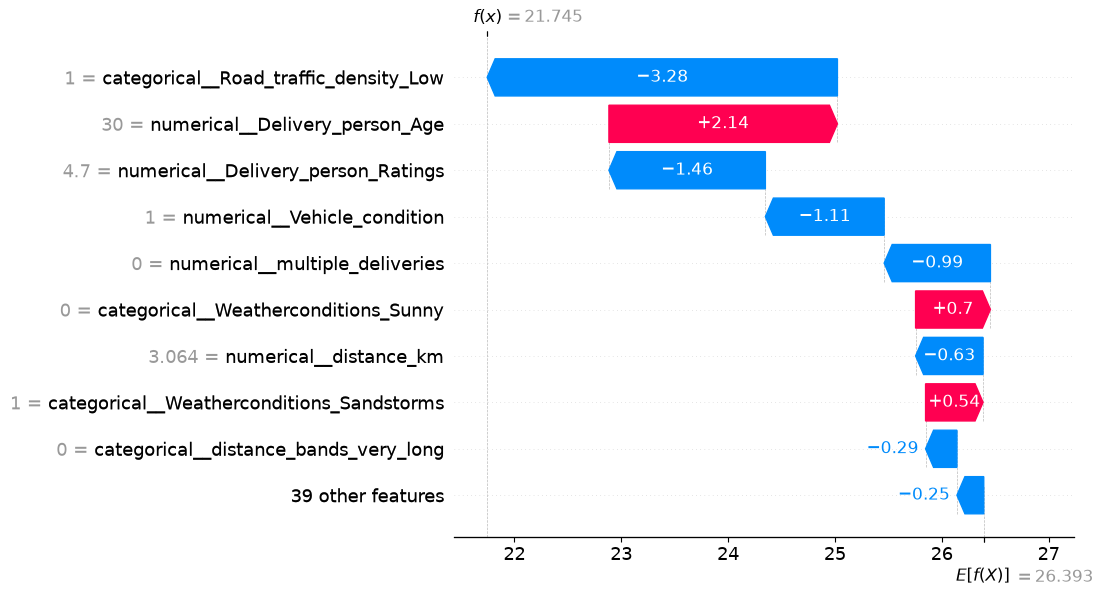

In [73]:
# Display the local SHAP explanation for this individual delivery.
# Positive SHAP values push the prediction higher; negative values push it lower.
shap.waterfall_plot(shap.Explanation(
    values = sample_shap_values,
    base_values=explainer.expected_value,
    data = sample_features[0],
    feature_names = feature_names
))

# phase - 7
* LATE DELIVERY RISK CLASSIFICATION

In [74]:
# Define a configurable operational threshold for late delivery.
# The source dataset provides actual delivery time but no promised-delivery timestamp,
# so we explicitly define 30 minutes as the project's initial late-delivery threshold.

LATE_THRESHOLD_MINUTES = 30
print(
    f" Late_delivery threshold :"
    f"{LATE_THRESHOLD_MINUTES} minutes"
)

 Late_delivery threshold :30 minutes


In [75]:
# create the classification target
# Convert the continuous delivery-time target into a binary classification target.
# 1 means the delivery reached or exceeded the operational threshold;
# 0 means it remained below the threshold.
y_train_late = (
    y_train >= LATE_THRESHOLD_MINUTES
).astype(int)

y_validation_late = (y_validation >= LATE_THRESHOLD_MINUTES).astype(int)

print("Training late-delivery distributions :")
print(y_train_late.value_counts())

print("\nValidation late-delivery distribution : ")
print(y_validation_late.value_counts())

Training late-delivery distributions :
target_delivery_time
0    18795
1     9239
Name: count, dtype: int64

Validation late-delivery distribution : 
target_delivery_time
0    4900
1    2150
Name: count, dtype: int64


In [76]:
# calculate percentage 
# Percentages help us understand class balance before choosing classification metrics.
# This is important because accuracy can be misleading when one class dominates.

print("Training distribution :")
print(
    y_train_late.value_counts(normalize=True).mul(100).round(2)
)

print("\nValidation distribution :")
print(
    y_validation_late.value_counts(normalize=True).mul(100).round(2)
)


Training distribution :
target_delivery_time
0    67.04
1    32.96
Name: proportion, dtype: float64

Validation distribution :
target_delivery_time
0    69.5
1    30.5
Name: proportion, dtype: float64


In [77]:
# Building with baseline classifier
# We'll start with Logistic regression

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
# Logistic Regression provides a transparent classification baseline.
# The same preprocessing strategy is reused so that categorical variables
# and missing values are handled consistently.
classification_numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

classification_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            classification_numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

logistic_classifier = Pipeline(
    steps=[
        (
            "preprocessor",
            classification_preprocessor
        ),
        (
            "Model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


In [78]:
# Train the classifier
# Fit the baseline classifier using only the training period.
# The validation period remains untouched until prediction/evaluation.

logistic_classifier.fit(
    X_train,y_train_late
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Delivery_person_Age','Delivery_person_Ratings','Restaurant_latitude',..., 'multiple_deliveries','Festival','City']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [79]:
# obtain both class prediction and probabilities :
# Class predictions are used for the confusion matrix and threshold-based metrics.
# Probabilities are needed for ROC-AUC, PR-AUC, and future risk scoring.

y_validation_late_pred = (logistic_classifier.predict(X_validation))
y_validation_late_prob = logistic_classifier.predict_proba(X_validation)[:,1]


print("First 10 prediction classes :")
print(y_validation_late_pred[:10])

print("\nFirst 10 delivery probabilities :")
print(y_validation_late_prob[:10])

First 10 prediction classes :
[0 1 1 0 1 0 0 0 0 0]

First 10 delivery probabilities :
[0.00155299 0.6652044  0.91992473 0.27066183 0.89846137 0.27711286
 0.34069809 0.35465353 0.0017431  0.0067204 ]


In [80]:
# Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [81]:
# Evaluate the classifier using metrics that are appropriate for a potentially
# imbalanced risk-detection problem.

logistic_accuracy = accuracy_score(
    y_validation_late,
    y_validation_late_pred
)

logistic_precision = precision_score(
    y_validation_late,y_validation_late_pred,zero_division=0
) 

logistic_recall = recall_score(
    y_validation_late,y_validation_late_pred,zero_division=0
)

logistic_f1 = f1_score(
    y_validation_late,
    y_validation_late_pred,
    zero_division=0
)

logistic_roc_auc = roc_auc_score(
    y_validation_late,
    y_validation_late_prob
)

logistic_pr_auc = average_precision_score(
    y_validation_late,
    y_validation_late_prob
)

print("Logistic Regression - Validation")
print("--------------------------------")
print(f"Accuracy : {logistic_accuracy:.3f}")
print(f"Precision: {logistic_precision:.3f}")
print(f"Recall   : {logistic_recall:.3f}")
print(f"F1       : {logistic_f1:.3f}")
print(f"ROC-AUC  : {logistic_roc_auc:.3f}")
print(f"PR-AUC   : {logistic_pr_auc:.3f}")

Logistic Regression - Validation
--------------------------------
Accuracy : 0.874
Precision: 0.820
Recall   : 0.752
F1       : 0.785
ROC-AUC  : 0.933
PR-AUC   : 0.881


In [82]:
# Confusion MAtrix
# The confusion matrix shows how many deliveries were correctly or incorrectly
# classified as late/non-late.

cm = confusion_matrix(
    y_validation_late,
    y_validation_late_pred
)

print("confusion Matrix :")
print(cm)

confusion Matrix :
[[4546  354]
 [ 533 1617]]


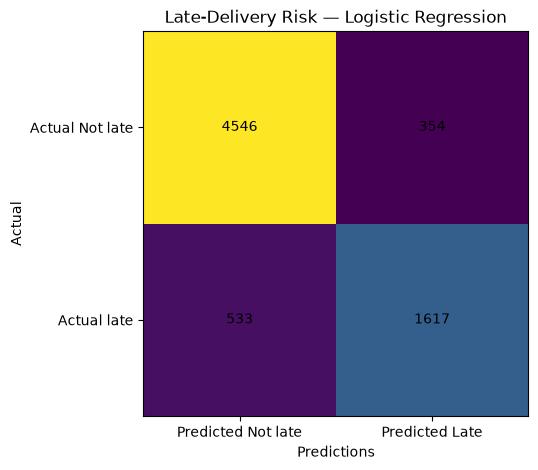

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize = (6,5))
plt.imshow(cm)
plt.xticks([0,1],["Predicted Not late","Predicted Late"])

plt.yticks([0,1],["Actual Not late","Actual late"])

plt.xlabel("Predictions")
plt.ylabel("Actual")
plt.title("Late-Delivery Risk — Logistic Regression")

for i in range(2) :
    for j in range(2) :
        plt.text(j,i,cm[i,j],ha = 'center',va = 'center')

plt.show()

**Phase 7.2**

In [84]:
# building XGBOoost classifier

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

# XGBoost Classifier is our nonlinear classification model.
# We reuse the existing preprocessing pipeline so that missing values and
# categorical variables are handled exactly as they were for the regression model.

xgb_classifier = Pipeline(
    steps = [
        (
            "preprocessor",
            preprocessor
        ),
        (
            "Model",
            XGBClassifier(objective = "binary:logistic",
                          n_estimators = 300,
                          learning_rate = 0.05,
                          max_depth = 6,
                          subsample = 0.8,
                          colsample_bytree = 0.8,
                          random_state = 42,
                          n_jobs = -1,
                          eval_metric = "logloss"
                          )
        )
    ]
)

In [85]:
# Train the classifier
xgb_classifier.fit(
    X_train,y_train_late
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('Model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['Delivery_person_Age','Delivery_person_Ratings','Restaurant_latitude',..., 'multiple_deliveries','Festival','City']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of 

In [86]:
y_validation_xgb_late_pred = (xgb_classifier.predict(X_validation))

y_validation_xgb_late_prob = (xgb_classifier.predict_proba(X_validation)[:,1])

print('First 10 predicted classes :')
print(y_validation_xgb_late_pred[:10])

print("\nFirst 10 late_delivery probabilities :")
print(y_validation_xgb_late_prob[:10])

First 10 predicted classes :
[0 0 1 1 0 0 1 0 0 0]

First 10 late_delivery probabilities :
[2.9803866e-03 2.9908243e-01 9.9783832e-01 9.9037105e-01 3.6036456e-01
 2.7851060e-01 9.9863583e-01 1.1380352e-01 1.6723460e-04 1.0134957e-03]


In [87]:
# Evaluate the XGBoost Model
# we need to compare it against our logistic regression baseline using exactly the same validation dataset and metrics

xgb_late_accuracy = accuracy_score(
    y_validation_late,y_validation_xgb_late_pred
)

xgb_late_precision = precision_score(
    y_validation_late,y_validation_xgb_late_pred,zero_division=0
)

xgb_late_recall = recall_score(
    y_validation_late,
    y_validation_xgb_late_pred
)

xgb_late_f1 = f1_score(
    y_validation_late,
    y_validation_xgb_late_pred,
    zero_division=0
)

xgb_late_roc_auc = roc_auc_score(
    y_validation_late,
    y_validation_xgb_late_prob
)

xgb_late_pr_auc = average_precision_score(
    y_validation_late,
    y_validation_xgb_late_prob
)

print("XGBoost Classifier - Validation")
print("--------------------------------")
print(f"Accuracy : {xgb_late_accuracy:.3f}")
print(f"Precision: {xgb_late_precision:.3f}")
print(f"Recall   : {xgb_late_recall:.3f}")
print(f"F1       : {xgb_late_f1:.3f}")
print(f"ROC-AUC  : {xgb_late_roc_auc:.3f}")
print(f"PR-AUC   : {xgb_late_pr_auc:.3f}")

XGBoost Classifier - Validation
--------------------------------
Accuracy : 0.922
Precision: 0.919
Recall   : 0.818
F1       : 0.865
ROC-AUC  : 0.980
PR-AUC   : 0.962


In [88]:
# Comparing the two Models

classification_results = pd.DataFrame({
    "Model" : [
        "Logistic Regression",
        "XGBoost"
    ],
    "Accuracy" : [
        logistic_accuracy,
        xgb_late_accuracy
    ],
    "Precision" :[
        logistic_precision,
        xgb_late_precision
    ],
    "Recall" :[
        logistic_recall,
        xgb_late_recall
    ],
    "F1" :[
        logistic_f1,
        xgb_late_f1
    ],
    "ROC_AUC" : [
        logistic_roc_auc,
        xgb_late_roc_auc
    ],
    "PR-AUC" : [
        logistic_pr_auc,
        xgb_late_pr_auc
    ]
})

classification_results

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR-AUC
0,Logistic Regression,0.874184,0.820396,0.752093,0.784761,0.933453,0.880643
1,XGBoost,0.922411,0.918975,0.817674,0.865370,0.980445,0.962175


In [89]:
# lets check confusion matrix 
xgb_late_cm = confusion_matrix(
    y_validation_late,
    y_validation_xgb_late_pred
)
print("XGBoost Confusion Matrix :")
print(xgb_late_cm)

XGBoost Confusion Matrix :
[[4745  155]
 [ 392 1758]]


**Phase 7.3 classification threshold analysis**

In [90]:
# Evaluate several thershold
# Test several probability thresholds for converting model probabilities
# into binary late/not-late predictions.
#
# The model itself does not change here.
# Only the decision rule changes.

thresholds = np.arange(
    0.20,0.81,0.05
)

thresholds_results = []

for threshold in thresholds :
    predictions = (y_validation_xgb_late_prob >= threshold).astype(int)

    thresholds_results.append({
        "Threshold" : threshold,
        "Precision" : precision_score(y_validation_late,predictions,zero_division=0),

        "Recall" : recall_score(
            y_validation_late,
            predictions,zero_division=0
        ),

        "F1" : f1_score(
            y_validation_late,predictions,zero_division=0
        )
    })


thresholds_results = pd.DataFrame(thresholds_results)

thresholds_results

,Threshold,Precision,Recall,F1
0,0.20,0.727115,0.971628,0.831774
1,0.25,0.766029,0.950233,0.848246
2,0.30,0.797113,0.924651,0.856158
3,0.35,0.836222,0.897674,0.865859
4,0.40,0.865803,0.870233,0.868012
5,0.45,0.895751,0.843256,0.868711
6,0.50,0.918975,0.817674,0.865370
7,0.55,0.942810,0.789767,0.859529
8,0.60,0.969644,0.772558,0.859953
9,0.65,0.984281,0.757209,0.855941


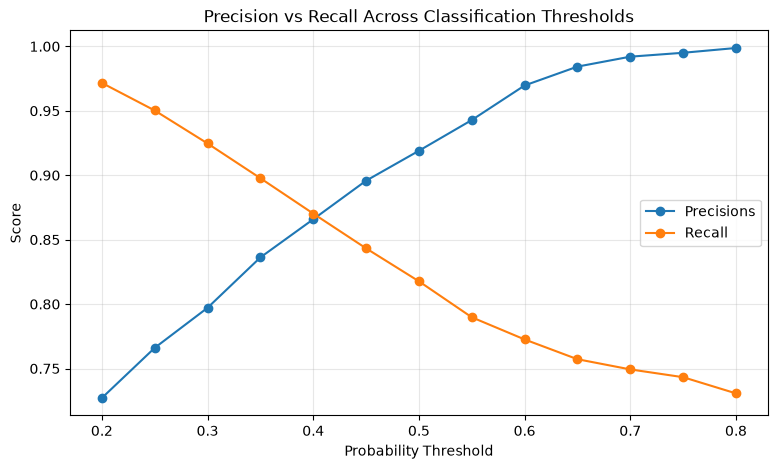

In [91]:
# Visualize the precision-recall trade-off across different thresholds.
# This helps us see how changing the alert threshold affects the operational
# balance between false alerts and missed late deliveries.

plt.figure(figsize=(9,5))

plt.plot(
    thresholds_results["Threshold"],
    thresholds_results["Precision"],
    marker = "o",
    label = "Precisions"
)

plt.plot(
    thresholds_results['Threshold'],
    thresholds_results['Recall'],
    marker = 'o',
    label = 'Recall'
)
plt.xlabel("Probability Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall Across Classification Thresholds")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [92]:
best_f1_row = (
    thresholds_results.loc[thresholds_results["F1"].idxmax()]
)

best_f1_row

Threshold    0.450000
Precision    0.895751
Recall       0.843256
F1           0.868711
Name: 5, dtype: float64

In [93]:
print(
    f"Best F1 threshold: "
    f"{best_f1_row['Threshold']:.2f}"
)

print(
    f"Precision: "
    f"{best_f1_row['Precision']:.3f}"
)

print(
    f"Recall: "
    f"{best_f1_row['Recall']:.3f}"
)

print(
    f"F1: "
    f"{best_f1_row['F1']:.3f}"
)

Best F1 threshold: 0.45
Precision: 0.896
Recall: 0.843
F1: 0.869


In [94]:
# Compare the default 0.50 threshold with the threshold that maximizes F1.
# This shows whether threshold optimization actually changes the model's
# operational behavior.

default_threshold = 0.50
default_predictions = (
    y_validation_xgb_late_prob >= default_threshold
).astype(int)

best_threshold = best_f1_row["Threshold"]

best_predictions = (
    y_validation_xgb_late_prob >= best_threshold
).astype(int)

threshold_comparison = pd.DataFrame({
    "Threshold": [
        default_threshold,
        best_threshold
    ],
    "Precision": [
        precision_score(
            y_validation_late,
            default_predictions,
            zero_division=0
        ),
        precision_score(
            y_validation_late,
            best_predictions,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_validation_late,
            default_predictions,
            zero_division=0
        ),
        recall_score(
            y_validation_late,
            best_predictions,
            zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_validation_late,
            default_predictions,
            zero_division=0
        ),
        f1_score(
            y_validation_late,
            best_predictions,
            zero_division=0
        )
    ]
})

threshold_comparison

,Threshold,Precision,Recall,F1
0,0.50,0.918975,0.817674,0.865370
1,0.45,0.895751,0.843256,0.868711


In [95]:
# Create calibration Bins
# What:
# Predicted late probabilities ko bins mein divide kar rahe hain.
#
# Why:
# Hume check karna hai ki predicted probability aur actual late rate
# ek doosre ke kitne close hain.
#
# Example:
# Agar model 0.7 probability wale deliveries deta hai,
# toh ideally unmein roughly 70% deliveries late honi chahiye.

calibration_df = pd.DataFrame({
    "predicted_probability" : y_validation_xgb_late_prob,
    "actual_late" : y_validation_late.values
})


calibration_df['probability_bin'] = pd.cut(
    calibration_df['predicted_probability'],
    bins = np.arange(0,1.1,0.1),
    include_lowest=True
)

calibration_summary = (
    calibration_df.groupby("probability_bin",observed = False).agg(deliveries = ('actual_late','size'),
                                                                   mean_predicted_probability =  ("predicted_probability",'mean'),
                                                                   actual_late_rate = ('actual_late','mean')).reset_index()
)

calibration_summary

,probability_bin,deliveries,mean_predicted_probability,actual_late_rate
0,"(-0.001, 0.1]",3881,0.010087,0.003865
1,"(0.1, 0.2]",296,0.152515,0.155405
2,"(0.2, 0.3]",379,0.247603,0.266491
3,"(0.3, 0.4]",333,0.347224,0.351351
4,"(0.4, 0.5]",248,0.445943,0.455645
5,"(0.5, 0.6]",200,0.546823,0.485000
6,"(0.6, 0.7]",89,0.640223,0.561798
7,"(0.7, 0.8]",51,0.756817,0.784314
8,"(0.8, 0.9]",92,0.852050,0.978261
9,"(0.9, 1.0]",1481,0.992041,1.000000


In [96]:
# calibration Curve
from sklearn.calibration import calibration_curve


fraction_of_positives,mean_predicted_values = calibration_curve(y_validation_late,y_validation_xgb_late_prob,n_bins = 10,strategy = 'uniform')

In [97]:
# Calculate Brier Score

# So it evaluates how good the probabilities themselves are, not just whether the final class is correct.

from sklearn.metrics import brier_score_loss

brier_Score = brier_score_loss(y_validation_late,y_validation_xgb_late_prob)

print(f"Brier Score : {brier_Score :.4f}")

Brier Score : 0.0497


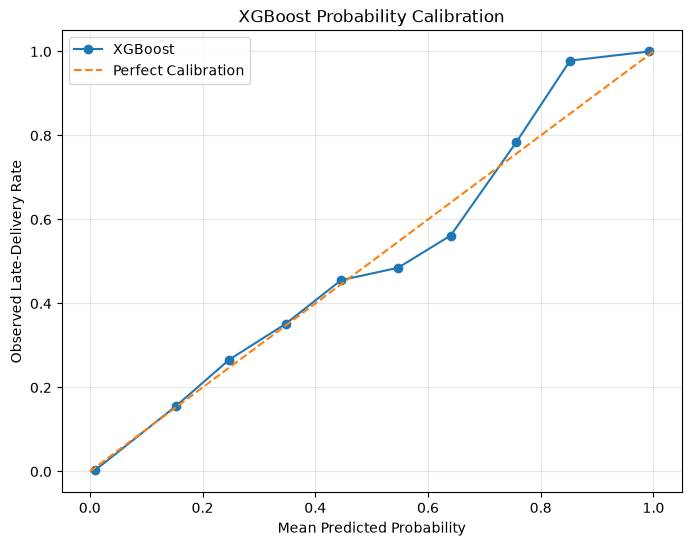

In [98]:
# plot

plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_values,
    fraction_of_positives,
    marker="o",
    label="XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Late-Delivery Rate")
plt.title("XGBoost Probability Calibration")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [99]:
def classify_delivery_risk(probability) :
     """
    Convert late-delivery probability into a business risk level.
    """
     if probability < 0.30 :
          return "Low Risk"

     elif probability < 0.60 :
          return "Medium Risk"

     else :
        return "High Risk"


In [100]:
def get_recommended_action(risk_level) :
     """
    Map delivery risk level to a recommended operational action.
    """
     if risk_level == 'Low Risk' :
          return "Normal Monitoring"

     elif risk_level == "Medium Risk" :
          return "Monitor delivery closely"

     else :
          return "Prioritize intervention"
     

In [101]:
# Sample Check
sample_probabilities = [0.15, 0.45, 0.82]

for probability in  sample_probabilities :
    risk = classify_delivery_risk(probability)
    action = get_recommended_action(risk)

    print( f"Late probability : {probability :.0%} | "
          f"Risk :{risk} | "
          f"Action : {action}")

Late probability : 15% | Risk :Low Risk | Action : Normal Monitoring
Late probability : 45% | Risk :Medium Risk | Action : Monitor delivery closely
Late probability : 82% | Risk :High Risk | Action : Prioritize intervention


In [102]:
# Evaluate business risk levels on the full validation set

risk_analysis = pd.DataFrame({
    "late_probability" : y_validation_xgb_late_prob,
    'actual_late' : y_validation_late.values
})

risk_analysis['risk_level'] = (
    risk_analysis["late_probability"].apply(classify_delivery_risk)
)
risk_summary = (
    risk_analysis.groupby("risk_level").agg(
        deliveries = ('actual_late','size'),
        actual_late_rate = ("actual_late","mean"),
        average_late_probability = ("late_probability",'mean')
    ).reset_index()
)
risk_summary['actual_late_rate'] *= 100
risk_summary["average_late_probability"] *=100

risk_summary

,risk_level,deliveries,actual_late_rate,average_late_probability
0,High Risk,1713,96.964390,95.924011
1,Low Risk,4556,3.555751,3.909829
2,Medium Risk,781,41.869398,42.968498


In [103]:
# Checking and testing the model on the X-test Data

y_test_eta_pred = tuned_xgb_model.predict(X_test)
test_eta_mae = mean_absolute_error(y_test,y_test_eta_pred)
test_eta_rmse = mean_squared_error(y_test,y_test_eta_pred)**0.5

test_eta_r2 = r2_score(y_test,y_test_eta_pred)

print("Final ETA Test Performance")
print(f"MAE : {test_eta_mae :.3f} minutes")
print(f"RMSE : {test_eta_rmse : .3f} minutes")
print(f"R2 : {test_eta_r2 : .3f}")

Final ETA Test Performance
MAE : 3.211 minutes
RMSE :  3.995 minutes
R2 :  0.821


In [104]:
# Create the late-delivery target for the untouched test set

y_test_late = (y_test >= LATE_THRESHOLD_MINUTES).astype(int)

print("Test late-delivery distribution:")
print(y_test_late.value_counts())
print("\nTest late-delivery percentage:")
print((y_test_late.value_counts(normalize=True) * 100).round(2))

Test late-delivery distribution:
target_delivery_time
0    4565
1    2304
Name: count, dtype: int64

Test late-delivery percentage:
target_delivery_time
0    66.46
1    33.54
Name: proportion, dtype: float64


In [105]:
# Final  late_delivery classification evaluations on untouched test data

y_test_xgb_late_prob = xgb_classifier.predict_proba(X_test)[:,1]
y_test_xgb_late_pred = (y_test_xgb_late_prob >= 0.45).astype(int)

test_accuracy = accuracy_score(y_test_late,y_test_xgb_late_pred)
test_precision = precision_score(y_test_late,y_test_xgb_late_pred)
test_recall = recall_score(y_test_late,y_test_xgb_late_pred)
test_f1 = f1_score(y_test_late,y_test_xgb_late_pred)
test_roc_auc = roc_auc_score(y_test_late,y_test_xgb_late_prob)
test_pr_auc = average_precision_score(
    y_test_late,
    y_test_xgb_late_prob)
test_brier = brier_score_loss(y_test_late,y_test_xgb_late_prob)

print("Final Late_Delivery Test Performance")
print(f"Accuracy :{test_accuracy:.3f}")
print(f"Precision: {test_precision:.3f}")
print(f"Recall   : {test_recall:.3f}")
print(f"F1       : {test_f1:.3f}")
print(f"ROC-AUC  : {test_roc_auc:.3f}")
print(f"PR-AUC   : {test_pr_auc:.3f}")
print(f"Brier    : {test_brier:.4f}")

Final Late_Delivery Test Performance
Accuracy :0.921
Precision: 0.889
Recall   : 0.875
F1       : 0.882
ROC-AUC  : 0.981
PR-AUC   : 0.968
Brier    : 0.0501


In [106]:
# final confusion matrix on untouched test Data
test_confusion_matrix = confusion_matrix(y_test_late,y_test_xgb_late_pred)

print('Final Test Confusion Matrix :')
print(test_confusion_matrix)

Final Test Confusion Matrix :
[[4313  252]
 [ 289 2015]]


**Phase-9 Explanability + Decision Time**

In [107]:
# Create a descision function

def generate_delivery_decision(
    predicted_eta,
    late_probability,
    risk_level) :

    """convert ML predcitions in to an operational recommendations
    """

    if risk_level == "High Risk" :
        recommendation = "Prioritize Intervention"

    elif risk_level == 'Medium Risk' :
        recommendation = "Monitor Delivery Closely"

    else :
        recommendation = 'Normal Monitoring'


    return {
        'predicted_eta_minutes' : round(predicted_eta,2) ,
        'late_probability' : round(late_probability,4),
        'risk_level' : risk_level,
        "recommendation" :recommendation
    }

In [108]:
# Test the decision engine
decision = generate_delivery_decision(
    predicted_eta=38.42,
    late_probability=0.91,
    risk_level = "High Risk"
)

decision

{'predicted_eta_minutes': 38.42,
 'late_probability': 0.91,
 'risk_level': 'High Risk',
 'recommendation': 'Prioritize Intervention'}

In [109]:
# create the prediction resposnse
def create_delivery_risk_response(predicted_eta,late_probability) :

    risk_level =  classify_delivery_risk(late_probability)

    decision = generate_delivery_decision(
        predicted_eta=predicted_eta,
        late_probability=late_probability,
        risk_level=risk_level
    )

    return decision

In [110]:
# Lets test it
sample_response = create_delivery_risk_response(predicted_eta=38.42,late_probability=0.91)

sample_response

{'predicted_eta_minutes': 38.42,
 'late_probability': 0.91,
 'risk_level': 'High Risk',
 'recommendation': 'Prioritize Intervention'}

In [111]:
# creating an SHAP explanation function :
def get_top_shap_features(
        shap_values_row,
        feature_names,
        top_n=5
) :
    # return the top feature contrbuting to an individual preediction

    explanation = pd.DataFrame({
        "feature" : feature_names,
        "shap_value" : shap_values_row
    })

    explanation['absolute_shap'] = (
        explanation['shap_value'].abs()
    )
    explanation = (
        explanation.sort_values("absolute_shap",ascending = False).head(top_n).reset_index(drop = True)
    )

    return explanation[
        ['feature','shap_value']
    ]

In [112]:
# lets test with the existing local SHAP example

top_features = get_top_shap_features(
    shap_values[0],
    feature_names,
    top_n=5
)

top_features

,feature,shap_value
0,categorical__Road_traffic_density_Low,-3.278234
1,numerical__Delivery_person_Age,2.138674
2,numerical__Delivery_person_Ratings,-1.464290
3,numerical__Vehicle_condition,-1.111881
4,numerical__multiple_deliveries,-0.994504


In [113]:
def format_shap_explanation(shap_explanation):
    """
    Convert processed SHAP feature names into
    business-friendly explanation labels.
    """

    explanation = shap_explanation.copy()

    explanation["feature"] = (
        explanation["feature"]
        .str.replace("categorical__", "", regex=False)
        .str.replace("numerical__", "", regex=False)
    )

    explanation["direction"] = explanation["shap_value"].apply(
        lambda value: "Increases ETA" if value > 0 else "Decreases ETA"
    )

    explanation["impact_minutes"] = (
        explanation["shap_value"].abs().round(2)
    )

    return explanation[
        ["feature", "direction", "impact_minutes"]
    ]

In [114]:
# testing

business_explanation = format_shap_explanation(top_features)

business_explanation

,feature,direction,impact_minutes
0,Road_traffic_density_Low,Decreases ETA,3.28
1,Delivery_person_Age,Increases ETA,2.14
2,Delivery_person_Ratings,Decreases ETA,1.46
3,Vehicle_condition,Decreases ETA,1.11
4,multiple_deliveries,Decreases ETA,0.99


In [115]:
# now we will combine prediction + risk + recommendation + explanation in to an single response

def build_explainable_delivery_response(
        predicted_eta,
        late_probability,
        shap_explanation
) :

    
    # Generate risk and business recommendation
    decision = create_delivery_risk_response(predicted_eta=predicted_eta,
                                             late_probability=late_probability)

    # Convert SHAP output into business-friendly explanations
    explanation = format_shap_explanation(shap_explanation)

    # Add explanation to the decision response
    decision['explanation'] = explanation.to_dict(orient = 'records')

    return decision



In [116]:
# Lets Test it 
final_sample_response = build_explainable_delivery_response(
    predicted_eta=38.42,
    late_probability=0.91,
    shap_explanation=top_features
)

final_sample_response

{'predicted_eta_minutes': 38.42,
 'late_probability': 0.91,
 'risk_level': 'High Risk',
 'recommendation': 'Prioritize Intervention',
 'explanation': [{'feature': 'Road_traffic_density_Low',
   'direction': 'Decreases ETA',
   'impact_minutes': 3.2799999713897705},
  {'feature': 'Delivery_person_Age',
   'direction': 'Increases ETA',
   'impact_minutes': 2.140000104904175},
  {'feature': 'Delivery_person_Ratings',
   'direction': 'Decreases ETA',
   'impact_minutes': 1.4600000381469727},
  {'feature': 'Vehicle_condition',
   'direction': 'Decreases ETA',
   'impact_minutes': 1.1100000143051147},
  {'feature': 'multiple_deliveries',
   'direction': 'Decreases ETA',
   'impact_minutes': 0.9900000095367432}]}

In [117]:
# Save the complete pipelines

import os
import joblib

# create model directory if it des not already exist
os.makedirs("../models",exist_ok = True)

# save the complete ETA regression pipeline
joblib.dump(
    tuned_xgb_model,"../models/eta_model.joblib"
)

# Save the complete late-delivery classification pipeline
joblib.dump(xgb_classifier,"../models/late_delivery_classifier.joblib")

print("Models artifacts saved successfully.")

Models artifacts saved successfully.


In [118]:
# verfying the same artifacts
import os
eta_model_path = "../models/eta_model.joblib"
classifier_model_path = "../models/late_delivery_classifier.joblib"

print("ETA model exists:", os.path.exists(eta_model_path))
print("Classifier exists:", os.path.exists(classifier_model_path))


print("\nSaved model files:")
print(os.listdir("../models"))

ETA model exists: True
Classifier exists: True

Saved model files:
['eta_model.joblib', 'late_delivery_classifier.joblib']


In [119]:
# Verify that the saved models can actually be loaded

import joblib
loaded_eta_model = joblib.load( "../models/eta_model.joblib")
loaded_classifier = joblib.load( "../models/late_delivery_classifier.joblib")

print("ETA model loaded :",type(loaded_eta_model))
print("Classifier model :",type(loaded_classifier))




ETA model loaded : <class 'sklearn.pipeline.Pipeline'>
Classifier model : <class 'sklearn.pipeline.Pipeline'>


In [120]:
import joblib
from pathlib import Path

# Paths to your saved models
MODEL_DIR = Path("../models")  # adjust relative to your notebook location
tuned_xgb_model = joblib.load(MODEL_DIR / "eta_model.joblib")
xgb_classifier = joblib.load(MODEL_DIR / "late_delivery_classifier.joblib")

In [121]:

# Check whether the required notebook variables exist.
required_variables = [
    "X_validation",
    "tuned_xgb_model",
    "xgb_classifier"
]

for variable in required_variables:
    print(f"{variable}: {variable in globals()}")


X_validation: True
tuned_xgb_model: True
xgb_classifier: True


In [122]:
# Find the reference prediction from the Notebook


required_features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "multiple_deliveries"
]

valid_rows = X_validation.dropna(subset=required_features)

sample_input = valid_rows.iloc[[0]].copy()

sample_input.T


,18037
Delivery_person_Age,36.0
Delivery_person_Ratings,4.0
Restaurant_latitude,22.74806
Restaurant_longitude,75.8934
Delivery_location_latitude,22.80806
Delivery_location_longitude,75.9534
distance_km,9.074745
distance_bands,long
pickup_hour,21
pickup_minute,59


In [123]:
# Select the complete validation row you just shared.
sample_input = X_validation.loc[[18037]].copy()

# Predict delivery time using the trained ETA pipeline.
notebook_eta = float(
    tuned_xgb_model.predict(sample_input)[0]
)

# Predict probability of late delivery.
notebook_late_probability = float(
    xgb_classifier.predict_proba(sample_input)[0, 1]
)

print("Notebook ETA:", round(notebook_eta, 4), "minutes")
print(
    "Notebook late probability:",
    round(notebook_late_probability, 6)
)
print(
    "Notebook late probability (%):",
    round(notebook_late_probability * 100, 2), "%"
)


Notebook ETA: 37.5857 minutes
Notebook late probability: 0.997838
Notebook late probability (%): 99.78 %


In [124]:
import joblib
from pathlib import Path

project_root = Path.cwd()

# If running from the notebooks folder, move to project root.
if project_root.name == "notebooks":
    project_root = project_root.parent

saved_eta_model = joblib.load(
    project_root / "models" / "eta_model.joblib"
)

saved_classifier = joblib.load(
    project_root / "models" / "late_delivery_classifier.joblib"
)

print(
    "ETA — in-memory:",
    tuned_xgb_model.predict(sample_input)[0]
)
print(
    "ETA — saved artifact:",
    saved_eta_model.predict(sample_input)[0]
)

print(
    "Classifier — in-memory:",
    xgb_classifier.predict_proba(sample_input)[0, 1]
)
print(
    "Classifier — saved artifact:",
    saved_classifier.predict_proba(sample_input)[0, 1]
)

ETA — in-memory: 37.58573
ETA — saved artifact: 37.58573
Classifier — in-memory: 0.9978383
Classifier — saved artifact: 0.9978383


In [125]:
# Show the exact values and data types used by the notebook.
print("NOTEBOOK INPUT:")
print(sample_input.iloc[0].to_dict())

print("\nNOTEBOOK DATA TYPES:")
print(sample_input.dtypes.to_dict())

# Show the exact prediction without rounding.
print("\nNOTEBOOK ETA:")
print(repr(float(tuned_xgb_model.predict(sample_input)[0])))

print("\nNOTEBOOK LATE PROBABILITY:")
print(repr(float(xgb_classifier.predict_proba(sample_input)[0, 1])))

NOTEBOOK INPUT:
{'Delivery_person_Age': 36.0, 'Delivery_person_Ratings': 4.0, 'Restaurant_latitude': 22.74806, 'Restaurant_longitude': 75.8934, 'Delivery_location_latitude': 22.80806, 'Delivery_location_longitude': 75.9534, 'distance_km': 9.074744674241003, 'distance_bands': 'long', 'pickup_hour': 21, 'pickup_minute': 59, 'pickup_day_of_week': 3, 'pickup_is_weekend': False, 'pickup_time_period': 'night', 'pickup_hour_sin': -0.7071067811865477, 'pickup_hour_cos': 0.7071067811865474, 'is_peak_pickup': True, 'Weatherconditions': 'Sandstorms', 'Road_traffic_density': 'Jam', 'Vehicle_condition': 0, 'Type_of_order': 'Drinks', 'Type_of_vehicle': 'motorcycle', 'multiple_deliveries': 0.0, 'Festival': 'No', 'City': 'Metropolitian'}

NOTEBOOK DATA TYPES:
{'Delivery_person_Age': dtype('float64'), 'Delivery_person_Ratings': dtype('float64'), 'Restaurant_latitude': dtype('float64'), 'Restaurant_longitude': dtype('float64'), 'Delivery_location_latitude': dtype('float64'), 'Delivery_location_longitude

In [127]:

import json
import requests
import numpy as np
import pandas as pd

API_URL = "http://127.0.0.1:8000/predict"

# Step 1: Find complete validation rows
complete_rows = X_validation.dropna()

print("Total validation rows:", len(X_validation))
print("Complete validation rows:", len(complete_rows))

if len(complete_rows) < 3:
    raise ValueError(
        "Fewer than 3 complete rows found. "
        "Check missing values in X_validation."
    )

# Step 2: Select first, middle, and last complete rows
candidate_rows = complete_rows.iloc[
    [0, len(complete_rows) // 2, len(complete_rows) - 1]
]

print("Selected row indices:", candidate_rows.index.tolist())
print("Selected shape:", candidate_rows.shape)

# Step 3: Compare notebook and API predictions
for row_index, row in candidate_rows.iterrows():

    # Convert the row into JSON-compatible values
    payload = json.loads(
        json.dumps(
            row.to_dict(),
            default=lambda value: (
                value.item()
                if isinstance(value, np.generic)
                else str(value)
            ),
            allow_nan=False
        )
    )

    # Notebook ETA prediction
    notebook_eta = float(
        tuned_xgb_model.predict(
            X_validation.loc[[row_index]]
        )[0]
    )

    # Notebook late-delivery probability
    notebook_late_probability = float(
        xgb_classifier.predict_proba(
            X_validation.loc[[row_index]]
        )[0, 1]
    )

    # FastAPI predictions
    response = requests.post(
        API_URL,
        json=payload,
        timeout=30
    )
    response.raise_for_status()
    api_result = response.json()

    print(f"\nValidation row: {row_index}")

    print(f"Notebook ETA: {notebook_eta:.10f}")
    print(f"API ETA:      {api_result['predicted_eta_minutes']:.10f}")
    print(
        "ETA matches:",
        np.isclose(
            notebook_eta,
            api_result["predicted_eta_minutes"],
            rtol=0,
            atol=1e-6
        )
    )

    print(
        f"Notebook late probability: "
        f"{notebook_late_probability:.10f}"
    )
    print(
        f"API late probability: "
        f"{api_result['late_probability']:.10f}"
    )
    print(
        "Probability matches:",
        np.isclose(
            notebook_late_probability,
            api_result["late_probability"],
            rtol=0,
            atol=1e-6
        )
    )

    print("Risk level:", api_result["risk_level"])
    print("Recommendation:", api_result["recommendation"])


Total validation rows: 7050
Complete validation rows: 6362
Selected row indices: [18037, 845, 16615]
Selected shape: (3, 24)

Validation row: 18037
Notebook ETA: 37.5857315063
API ETA:      37.5857315063
ETA matches: True
Notebook late probability: 0.9978383183
API late probability: 0.9978383183
Probability matches: True
Risk level: High Risk
Recommendation: Prioritize intervention

Validation row: 845
Notebook ETA: 46.3929328918
API ETA:      46.3929328918
ETA matches: True
Notebook late probability: 0.9977530837
API late probability: 0.9977530837
Probability matches: True
Risk level: High Risk
Recommendation: Prioritize intervention

Validation row: 16615
Notebook ETA: 27.1619338989
API ETA:      27.1619338989
ETA matches: True
Notebook late probability: 0.3190039992
API late probability: 0.3190039992
Probability matches: True
Risk level: Medium Risk
Recommendation: Monitor delivery closely
